In [30]:
import pandas as pd
from matplotlib import pyplot as plt

bench = pd.read_csv("results/bench.csv")
bench["hashes_per_s"] = bench["n"] / (bench["us"] / 1e6)
stab = pd.read_csv("results/stability.csv")
stab["hashes_per_s"] = stab["n"] / (stab["us"] / 1e6)

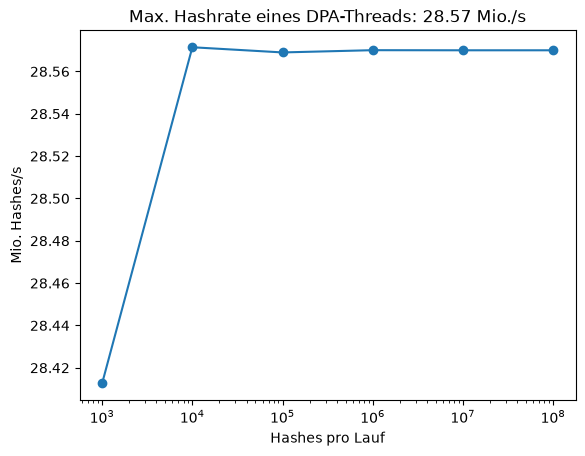

In [31]:
mean = bench.groupby("n")["hashes_per_s"].mean()
#plt.plot(bench["n"], bench["hashes_per_s"] / 1e6, ".", color="grey")
plt.plot(mean.index, mean.values / 1e6, "o-")
plt.xscale("log")
plt.ticklabel_format(axis="y", useOffset=False)
plt.xlabel("Hashes pro Lauf")
plt.ylabel("Mio. Hashes/s")
plt.title(f"Max. Hashrate eines DPA-Threads: {mean.max() / 1e6:.2f} Mio./s")
plt.show()

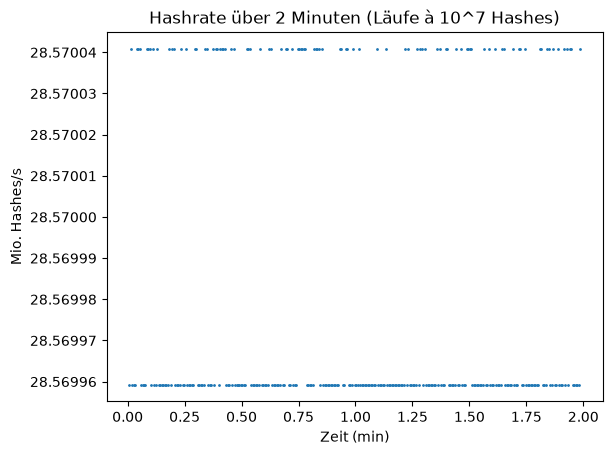

In [32]:
plt.plot(stab["t_s"] / 60, stab["hashes_per_s"] / 1e6, ".", markersize=2)
plt.ticklabel_format(axis="y", useOffset=False)
plt.xlabel("Zeit (min)")
plt.ylabel("Mio. Hashes/s")
plt.title("Hashrate über 2 Minuten (Läufe à 10^7 Hashes)")
plt.show()

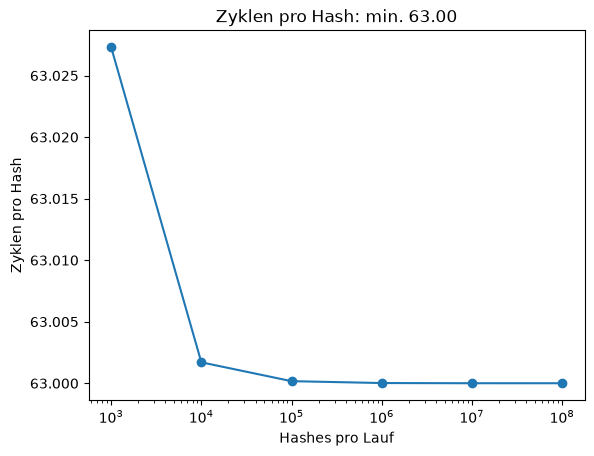

In [33]:
bench["cycles_per_hash"] = bench["cycles"] / bench["n"]
mean_cyc = bench.groupby("n")["cycles_per_hash"].mean()
plt.plot(mean_cyc.index, mean_cyc.values, "o-")
plt.xscale("log")
plt.ticklabel_format(axis="y", useOffset=False)
plt.xlabel("Hashes pro Lauf")
plt.ylabel("Zyklen pro Hash")
plt.title(f"Zyklen pro Hash: min. {mean_cyc.min():.2f}")
plt.show()
